# Can QML choose the optimal ensemble?

**IQ Hackathon Fall 2026 — exploratory extension**

기존 6개 예측 모델 중 2개를 선택하는 QML 선택기를 고전 선택기 및 전체 평균과 비교합니다.
‘최적’은 다음 달 실제 Brier 손실이 가장 작은 **15개 동일 가중치 모델 쌍 중 하나**로 정의합니다.
미래 결과를 아는 oracle은 선택기의 평가 기준으로만 사용합니다.

The four-qubit quantum kernel learns a context-dependent loss estimate for each
pair. It does not guarantee a globally optimal ensemble or a quantum speedup.
This notebook reruns the experiment, displays its executed results, and checks provenance.

**Data status:** the underlying dataset and earlier results were already examined.
This is an exploratory extension, not an independent holdout or a new confirmatory study.

## 1. Environment and source

Open this notebook from the repository root. In a fresh Python environment,
uncomment the minimal dependency installation below. Base forecasts and frozen
prices are included in the repository; this experiment requires no network data.
For Colab, first clone the repository and change into its root using the commented commands.

In [1]:
# Fresh environment / Colab setup (uncomment if needed):
# !git clone https://github.com/Futuremine97/IQ_Hackathon_Fall_2026.git
# %cd IQ_Hackathon_Fall_2026
# %pip install numpy pandas scipy matplotlib

import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd()
assert (ROOT / 'run_ensemble_selector.py').exists(), 'Run from the repository root.'
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, 'Pandas:', pd.__version__)
display(Markdown((ROOT / 'ENSEMBLE_PROTOCOL.md').read_text()))

Python: 3.12.13
NumPy: 2.5.4 Pandas: 3.1.0


# Quantum ensemble selector: exploratory protocol

Written before running `run_ensemble_selector.py`. This is an exploratory reuse of
an already examined dataset, not a new confirmatory preregistration.

Question: can a four-qubit quantum fidelity kernel learn which equal-weight pair
of six saved ETF forecasters will have the lowest next-month Brier loss?
Experts: Prophet, momentum, QSVM, RBF SVM, logistic regression and VQC. Convert
each month's scores to (rank - 0.5)/18; these are rank scores, not calibrated
probabilities. Enumerate all 15 pairs. Primary loss is mean squared error of the
pair's mean rank score against the top-half label. Secondary metric: top-9 accuracy.
The scope of optimality is these 15 equal-weight pairs and this loss, not all
possible ensemble sizes, continuous weights, or future performance.

Use saved walk-forward base predictions without refitting them. Verify their
labels and returns against the frozen price panel. At decision t, use only past
labels with label_end <= t. Four context features: preceding three months' average
expert loss, preceding three months' quantum-minus-classical expert loss,
last resolved month's average asset return, and its cross-sectional dispersion.
Scale with training means and standard deviations, then arctan to (0,1), identically
for quantum and classical kernels. Predict centered losses for all 15 pairs by
kernel ridge regression and select the lowest predicted loss (stable ties).

Warm-up: 2014-2015 (minimum 18 usable context rows). Select hyperparameters using
walk-forward mean selected-pair Brier loss in 2016-2018 only. Quantum: ZZ product
map, two repetitions, scale in {0.1,0.3,1}; classical: RBF gamma in {0.1,1,10}.
Both ridge penalties in {0.01,0.1,1}: nine configurations each. Freeze for evaluation
2019-01 through 2026-08; expand training monthly with resolved labels.

Baselines: all-six equal weight, fixed best pair from pre-2019 data, expanding
historical best pair, trailing-12-month best pair, and uniform random pair's exact
expected metrics. An explicitly non-deployable hindsight oracle chooses the
lowest realized Brier loss each month. Report optimum hit rate (ties allowed),
regret to that oracle, and paired Brier difference vs RBF. A 6-month circular block
bootstrap (10,000 replicates, fixed seed 2026) gives a 95% interval. Evidence for
QML benefit requires that interval to be strictly positive for RBF minus quantum,
and QML mean loss below all-six, fixed, expanding, trailing, and random baselines.

Controls: normalized positive-semidefinite quantum Gram matrix, a synthetic
kernel-generated target learned better than its constant predictor, chronological
assertions, unchanged past predictions after perturbing future target rows, and
100 independent within-month asset-label shuffles evaluated with the original
selections (a scoring sanity check, not a retrained learning null). Failures void
the result. Simulation only: no hardware or computational advantage claim.

Reference: Havlicek et al. (2019),
https://www.nature.com/articles/s41586-019-0980-2 .


## 2. Candidate pairs and chronological evaluation

Experts: Prophet, momentum, QSVM, RBF SVM, logistic regression, and VQC. Map
each expert's 18 scores to `(rank - 0.5)/18`, then average the two selected experts.
These scores are **not calibrated probabilities**. Pair loss is the mean squared
error against next-month top-half labels; accuracy classifies the nine highest scores.

At date $t$, historical labels must satisfy `label_end <= t` and `date < t`.
The four inputs are lagged mean expert loss, lagged quantum-minus-classical loss,
last resolved mean return, and last resolved cross-sectional return dispersion.
Scaling is fitted only on each training window.

* Warm-up: 2014–2015; minimum 18 usable training months.
* Tuning: walk-forward 2016–2018, nine configurations per kernel.
* Evaluation: 2019-01 through 2026-08; frozen hyperparameters, expanding training.

The quantum model uses a four-qubit ZZ fidelity kernel with two feature-map repetitions.
Both kernels use centered multi-output kernel ridge regression to predict all 15 losses.
The pair with the smallest predicted loss is selected before the next-month outcome.

In [2]:
from run_ensemble_selector import EXPERTS, PAIR_NAMES, load_inputs, main

x, losses, ends, dates, pair_scores, expert_scores, labels, source_hash = load_inputs()
display(pd.DataFrame({'pair_id': range(len(PAIR_NAMES)), 'experts': PAIR_NAMES}))
print('Usable monthly contexts:', len(dates), '| Context dimensions:', x.shape[1])
print('Saved base-forecast SHA256:', source_hash)
assert x.shape[1] == 4 and losses.shape[1] == 15

,pair_id,experts
0,0,p_ret+mom_12_1
1,1,p_ret+qsvm
2,2,p_ret+rbf
3,3,p_ret+logit
4,4,p_ret+vqc
5,5,mom_12_1+qsvm
6,6,mom_12_1+rbf
7,7,mom_12_1+logit
8,8,mom_12_1+vqc
9,9,qsvm+rbf


Usable monthly contexts: 149 | Context dimensions: 4
Saved base-forecast SHA256: 92462196cc18e5ade280f8ec618eacaaa2bbf3aeb73465a564db43ba6638cbb7


## 3. Rerun the complete experiment

This cell regenerates `results/ensemble_selector/RESULT.json`, `monthly.csv`, and
`REPORT.md`. Seeds, grids, split dates, and the decision rule are fixed in source.
The original base forecasters are loaded from their saved walk-forward predictions.

In [3]:
main()
OUT = ROOT / 'results' / 'ensemble_selector'
result = json.loads((OUT / 'RESULT.json').read_text())
monthly = pd.read_csv(OUT / 'monthly.csv', parse_dates=['date'])
assert result['input_scores_sha256'] == source_hash
assert result['protocol_sha256'] == hashlib.sha256((ROOT / 'ENSEMBLE_PROTOCOL.md').read_bytes()).hexdigest()
assert not monthly.duplicated(['date', 'arm']).any()
print('Evaluation:', result['eval_start'], 'to', result['eval_end'])
print('Months:', result['n_eval_months'])
print('Selected hyperparameters (kernel scale, ridge):', result['selected_hyperparameters'])

quantum selected (0.3, 0.01)


rbf selected (1.0, 0.1)


                            brier  accuracy  oracle_hit    regret
arm                                                              
all_six                  0.276494  0.524155         NaN  0.041146
expanding                0.294113  0.502415    0.032609  0.058765
fixed                    0.292611  0.498792    0.130435  0.057263
hindsight_oracle         0.235348  0.606280    1.000000  0.000000
quantum                  0.301850  0.495169    0.043478  0.066502
random_pair_expectation  0.297597  0.507407         NaN  0.062249
rbf                      0.297816  0.497585    0.086957  0.062468
trailing12               0.297005  0.502415    0.054348  0.061657


NO_QML_BENEFIT_DEMONSTRATED [-0.014311151555138077, 0.0056593681040138346]


Evaluation: 2019-01-31 to 2026-08-31
Months: 92
Selected hyperparameters (kernel scale, ridge): {'quantum': [0.3, 0.01], 'rbf': [1.0, 0.1]}


## 4. Results and baselines

Lower Brier loss is better. The hindsight oracle knows next month's realized
losses and cannot be deployed. The random-pair baseline reports exact expected
metrics over all 15 pairs. The all-six average lies outside the pair candidate set.
The fixed pair is chosen using only data resolved before the evaluation begins.

In [4]:
summary = pd.DataFrame(result['arms']).T.sort_values('brier')
display(summary.rename(columns={'brier': 'Brier loss ↓', 'accuracy': 'Top-9 accuracy',
                                'oracle_hit': 'Optimal-pair hit', 'regret': 'Brier regret ↓'})
        .style.format({'Brier loss ↓': '{:.6f}', 'Top-9 accuracy': '{:.2%}',
                       'Optimal-pair hit': '{:.2%}', 'Brier regret ↓': '{:.6f}'}, na_rep='—'))
print('Verdict:', result['verdict'])

,Brier loss ↓,Top-9 accuracy,Optimal-pair hit,Brier regret ↓
hindsight_oracle,0.235348,60.63%,100.00%,0.000000
all_six,0.276494,52.42%,—,0.041146
fixed,0.292611,49.88%,13.04%,0.057263
expanding,0.294113,50.24%,3.26%,0.058765
trailing12,0.297005,50.24%,5.43%,0.061657
random_pair_expectation,0.297597,50.74%,—,0.062249
rbf,0.297816,49.76%,8.70%,0.062468
quantum,0.301850,49.52%,4.35%,0.066502


Verdict: NO_QML_BENEFIT_DEMONSTRATED


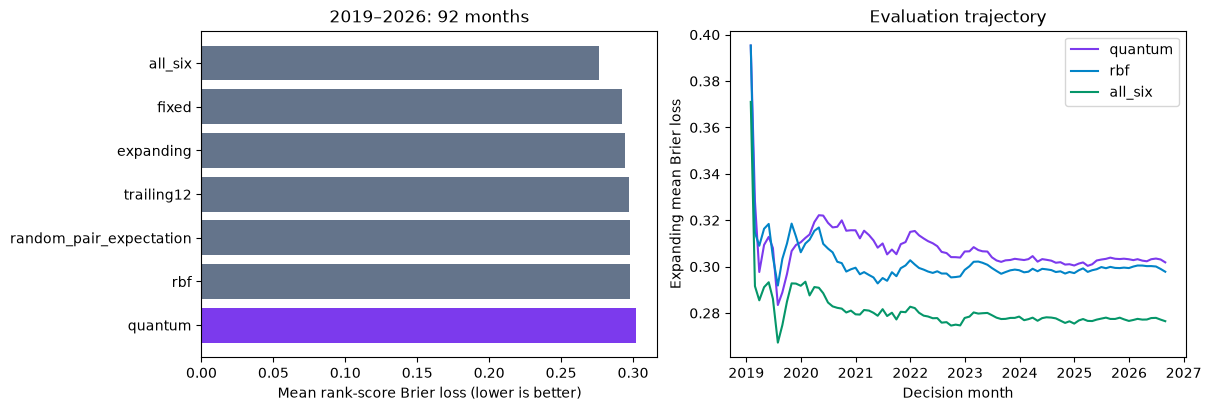

In [5]:
deployable = summary.drop(index='hindsight_oracle')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
colors = ['#7c3aed' if arm == 'quantum' else '#64748b' for arm in deployable.index]
axes[0].barh(deployable.index, deployable.brier, color=colors)
axes[0].invert_yaxis()
axes[0].set(xlabel='Mean rank-score Brier loss (lower is better)', title='2019–2026: 92 months')
wide = monthly.pivot(index='date', columns='arm', values='brier')
for arm, color in [('quantum', '#7c3aed'), ('rbf', '#0284c7'), ('all_six', '#059669')]:
    axes[1].plot(wide.index, wide[arm].expanding().mean(), label=arm, color=color)
axes[1].set(xlabel='Decision month', ylabel='Expanding mean Brier loss', title='Evaluation trajectory')
axes[1].legend()
plt.show()

## 5. Uncertainty, optimum selection, and controls

The primary comparison is paired **RBF minus QML Brier loss**. Positive values
favor QML. The 95% interval uses 10,000 circular block-bootstrap replicates with
six-month blocks. The interval conditions on the chosen hyperparameters.
Evidence of QML benefit additionally requires lower mean loss than every deployable baseline.

An optimal-pair hit means the chosen pair ties the lowest realized Brier loss
among the 15 pairs. This does not imply best accuracy or investment return.

In [6]:
delta = result['rbf_minus_quantum_brier']
low, high = result['block_bootstrap_95_ci']
print(f'RBF minus QML Brier: {delta:.6f}; 95% block-bootstrap CI [{low:.6f}, {high:.6f}]')
print(f"QML optimal-pair hit rate: {summary.loc['quantum', 'oracle_hit']:.2%}")
display(pd.Series(result['controls'], name='Control result').to_frame())
display(monthly.loc[monthly.arm == 'quantum', 'pair'].value_counts().rename('Months selected').to_frame())
assert result['controls']['future_target_invariance']
assert result['controls']['fixed_selection_shuffle_pass']
assert result['controls']['planted_mse'] < result['controls']['planted_constant_mse']

RBF minus QML Brier: -0.004034; 95% block-bootstrap CI [-0.014311, 0.005659]
QML optimal-pair hit rate: 4.35%


,Control result
gram_normalized_psd,True
planted_mse,0.000017
planted_constant_mse,0.389326
future_target_invariance,True
frozen_labels_returns_match,True
chronology_assertions,True
fixed_selection_shuffle_mean_accuracy,0.497512
fixed_selection_shuffle_pass,True


,Months selected
pair,
p_ret+rbf,13
qsvm+rbf,12
p_ret+vqc,11
p_ret+qsvm,10
mom_12_1+vqc,9
logit+vqc,6
rbf+vqc,5
mom_12_1+logit,5
mom_12_1+rbf,5


## 6. Interpretation and reproducibility

**이번 실험에서는 QML 선택기의 개선을 확인하지 못했습니다.**
The quantum selector has higher Brier loss than RBF and the all-six average;
the RBF comparison interval includes zero. This is evidence about this specific
setup, not a universal impossibility result for quantum ensemble selection.

Controls verify frozen labels and returns, chronological training, future-target
invariance, a normalized PSD quantum Gram matrix, and learnability of a synthetic
kernel signal. Shuffled labels with fixed selections check scoring sanity;
they are not a retrained selector null experiment.

Limits: previously examined data; no fresh holdout; 92 monthly evaluations;
uncalibrated rank scores; only equal-weight pairs; one fixed context design;
noiseless classical quantum simulation. No hardware speedup or trading claim.

Files: `ENSEMBLE_PROTOCOL.md`, `run_ensemble_selector.py`, and
`results/ensemble_selector/{RESULT.json,monthly.csv,REPORT.md}`.
Rebuild this notebook with `python make_ensemble_notebook.py`, then run all cells.

Quantum feature-space reference:
[Havlíček et al., Nature (2019)](https://www.nature.com/articles/s41586-019-0980-2).